<a href="https://colab.research.google.com/github/jsellerfors/AH2179/blob/main/Lab1_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Course AH2174/FAH3002 - Traffic Simulation Modeling and Applications   
Lab 1,
Author: Pengnan Chi

Question. If vehicles arrive according to a Poisson process with an arrival rate of λ, what is the probability distribution of the time until the next vehicle arrives?

Answer. Exponential distribution with an expected mean of
$\frac{1}{\lambda}$, i.e., $f(t) = \lambda e^{-\lambda t}$.

Hints for Proof.
  - What is the probability of \textbf{no} arrivals in the \textbf{time interval} $0 \sim t$?
  - What is the probability of arrival in the \textbf{time interval} $0 \sim t$?
  - What is the probability of arrival at the \textbf{time point} $t$?


# Single Server Queueing Simulation Algorithm

$\textbf{Terms}$
* $\lambda$: arrival rate, `arrival_rate`
* $\mu$: service rate, `service_rate`
* $T$: close time, `close_time`
* $t$: current time, `time`
* $N_A$: total number of arrivals, `N_arrivals`
* $N_D$: total number of departures, `N_departures`
* $n$: queue length, `n`
* $t_A$: next arrival time, `t_arrival`
* $t_D$: next departure time, `t_departure`
* $X$: arrival time
* $Y$: service time
* $A$: arrival time for each vehicle    , `A`
* $D$: departure time for each vehicle, `D`
* $q$: queue length for each recording time, `queue`



$\textbf{Initialization}$
1. $t=N_A =N_D = n \leftarrow 0$
2. Generate $X$, $t_A \leftarrow 0 + X$
3. $t_D \leftarrow  \infty$


$\textbf{Simulation}$
*   if $t_A \leq t_D$ and $t_A \leq T$:
    *   $t \leftarrow  t_A$
    *   $n \leftarrow n + 1$
    *   $q \ \text{appends}  \ [n; t]$
    *   $N_A \leftarrow N_A + 1$
    *   $A \ \text{appends}  \ [N_A; t]$
    *   $t_A \leftarrow t + X$
    *   if $n = 1$:
        *   $t_D \leftarrow t + Y$

*   if $t_D < t_A$ and $t_D \leq T$:
    *   $t = t_D$
    *   $n = n - 1$
    *   $q \ \text{appends}  \ [n; t]$
    *   $N_D \leftarrow N_D + 1$
    *   $D \ \text{appends}  \ [N_D; t]$
    *   if $n = 0$:
        *   $t_D \leftarrow \infty$
    *   else:
        *   $t_D \leftarrow t + Y$

*   if $t_A > T$ and $t_D > T$:
    *   while $n > 0$:
        *   $t = t_D$
        *   $n = n - 1$
        *   $q \ \text{appends}  \ [n; t]$
        *   $N_D \leftarrow N_D + 1$
        *   $D \ \text{appends}  \ [N_D; t]$
        *   if $n > 0$:
            *   $t_D \leftarrow t + Y$

    *   if $n=0$:
        *   break






Complete `SingleServerQueueingSimulation` by filling the code under "`YOU CODE HERE`". You can also change the rest of the code skeleton according to your need!

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

class SingleServerQueueingSimulation():
    """
    This class simulates a single-server queueing system using discrete event simulation.
    The system models customer arrivals and service at a single server.
    It collects data on queue length, arrival times, and departure times.
    """

    def __init__(self, arrival_rate, service_rate, close_time):
        """
        Initializes the simulation with the given parameters.

        Parameters:
        - arrival_rate: The rate (per minute) at which customers arrive.
        - service_rate: The rate (per minute) at which the server can serve customers.
        - close_time: The time (in minutes) after which no new customers are allowed to join the queue.
        """
        self.arrival_rate = arrival_rate  # Set the customer arrival rate.
        self.service_rate = service_rate  # Set the service rate for the server.
        self.close_time = close_time  # Time after which no new arrivals are permitted.

        # Use a exponential random number generator with different seeds to model arrival and service times in simulation runs.
        self.arrival_rng = np.random.default_rng(seed=42)
        self.service_rng = np.random.default_rng(seed=123)

        # Dictionary to store the results of each simulation run.
        self.simulation_records = {}

    def simulate(self):
        """
        Runs a single instance of the queueing simulation.

        Tracks the current time, the number of arrivals and departures, and records
        arrival and departure times. The simulation runs until all customers have been served
        after the system closes to new arrivals.

        Returns:
        - queue: A record of the number of vehicles in the queue over time.
        - A: A record of arrival times.
        - D: A record of departure times.
        """

        # Initialize simulation state variables
        t = 0
        n = 0
        N_A = 0
        N_D = 0

        queue = []
        A = []
        D = []
        S = []

        t_A = t + self.arrival_rng.exponential(
            scale=1/self.arrival_rate
        )

        t_D = np.inf

        # Main simulation loop to process events (arrivals or departures).
        while True:

            # Case 1: A customer arrives before the next departure and before the system closes.
            if t_A <= t_D and t_A <= self.close_time:

                t = t_A
                N_A += 1
                n += 1

                A.append(t)
                queue.append((t, n))

                t_A = t + self.arrival_rng.exponential(
                    scale=1/self.arrival_rate
                )

                if n == 1:
                    S.append(t)

                    t_D = t + self.service_rng.exponential(
                        scale=1/self.service_rate
                    )

            # Case 2: A customer departs before the next arrival and before the system closes.
            elif t_D < t_A and t_D <= self.close_time:

                t = t_D
                N_D += 1
                n -= 1

                D.append(t)
                queue.append((t, n))

                if n == 0:
                    t_D = np.inf

                else:
                    S.append(t)

                    t_D = t + self.service_rng.exponential(
                        scale=1/self.service_rate
                    )

            # Case 3: Stop the simulation if there are no more arrivals or departures.
            else:

                t_A = np.inf

                if n == 0:
                    break

                t = t_D
                N_D += 1
                n -= 1

                D.append(t)
                queue.append((t, n))

                if n == 0:
                    t_D = np.inf

                else:
                    S.append(t)

                    t_D = t + self.service_rng.exponential(
                        scale=1/self.service_rate
                    )

        # Convert lists to NumPy arrays for easier manipulation and analysis.
        queue = np.array(queue)
        A = np.array(A)
        D = np.array(D)
        S = np.array(S)

        # Return the recored queue states, arrival times, and departure times.
        return queue, A, D, S

    def run_multiple_simulations(self, n_simulations):
        """
        Runs the simulation multiple times and stores the results in simulation_records.

        Parameters:
        - n_simulations: Number of simulation runs to perform.

        Populates the simulation_records dictionary with the queue, arrival, and
        departure data for each simulation.
        """
        for i in range(n_simulations):
            queue, A, D, S = self.simulate()  # Run a single simulation.

            # Store the results in the simulation_records dictionary.
            self.simulation_records[f"round_{i}"] = {'queue': queue, 'A': A, 'D': D, 'S': S}
        return

    def compute_average_queue_length(self):
        """
        Computes the average queue length across all simulation runs.

        Returns:
        - The mean and standard deviation of the average queue length over all runs.
        """
        warm_up_period = 50 # Number of points to exclude from the start of the simulation
        average_queue_length = []  # List to store average queue lengths from each run.
        for values in self.simulation_records.values():
            queue = values['queue']  # Get the queue data for the current simulation.
            # Calculate the average queue length
            # NOTE: first points can be excluded, we only want the queue length in the steady state
            # NOTE: the number of vehicles in the queue is NOT evenly distributed along the simulation time
            #      find a way to weight the queue length by the time spent at each queue length

            # Exclude the first 50 recorded events
            queue = queue[warm_up_period:]

            # Extract event times and queue sizes
            times = queue[:, 0]
            lengths = np.maximum(queue[:, 1] - 1, 0)

            # Time between consecutive events
            time_intervals = np.diff(times)

            # Time-weighted average queue size
            queue_length = np.sum(
                lengths[:-1] * time_intervals
            ) / np.sum(time_intervals)

            # Store the result for this simulation run
            average_queue_length.append(queue_length)

        # Return the overall mean and standard deviation of the average queue lengths.
        return np.mean(average_queue_length), np.std(average_queue_length)

    def compute_average_waiting_time(self):
        """
        Computes the average waiting time for customers across all simulation runs.

        Returns:
        - The mean and standard deviation of the average waiting times across all runs.
        """
        warm_up_period = 50 # Number of points to exclude from the start of the simulation
        average_waiting_time = []  # List to store average waiting times from each run.
        for values in self.simulation_records.values():
            A = values['A']  # Get the arrival times.
            D = values['D']  # Get the departure times.

            # Calculate the average waiting time
            # Exclude the first 50 vehicles
            A = A[warm_up_period:]
            D = D[warm_up_period:]

            # Calculate each vehicle's total time in the system
            waiting_times = D - A

            # Calculate the average for this simulation run
            waiting_time = np.mean(waiting_times)

            # Store the average
            average_waiting_time.append(waiting_time)

        # Return the mean and standard deviation of the average waiting times.
        return np.mean(average_waiting_time), np.std(average_waiting_time)

    def get_simulation_records(self):
        """
        Retrieves the recorded data from all simulation runs.

        Returns:
        - A dictionary containing the queue, arrival, and departure data for each simulation run.
        {
            'round_0': {
                'queue': queue,
                'A': A,
                'D': D,
            },
            'round_1': {...},
            'round_2': {...},
            ...
        }
        """
        return self.simulation_records

# **Q1**

**What is the expected queue length?**

In [ ]:
arrival_rate = 15
close_time = 1000 #try different values
N = 100 #try different values

sim_06 = SingleServerQueueingSimulation(
    arrival_rate=arrival_rate,
    service_rate=15/0.6,
    close_time=close_time
)

sim_09 = SingleServerQueueingSimulation(
    arrival_rate=arrival_rate,
    service_rate=15/0.9,
    close_time=close_time
)

sim_06.run_multiple_simulations(N)
sim_09.run_multiple_simulations(N)

mean_06, std_06 = sim_06.compute_average_queue_length()
mean_09, std_09 = sim_09.compute_average_queue_length()

print("Intensity (rho) = 0.6")
print("Average queue lenght:", mean_06)

print("Intensity (rho) = 0.9")
print("Average queue length:", mean_09)

print(f"Std = {std_06:.2f}")
print(f"Std = {std_09:.2f}")

Intensity (rho) = 0.6
Average queue lenght: 0.8999271639233035
Intensity (rho) = 0.9
Average queue length: 8.11228261039107
Std = 0.04
Std = 1.30


**What is the variance of the queue lenght?**

In [ ]:
def compute_queue_variance(sim):

    variances = []

    for values in sim.get_simulation_records().values():

        queue = values["queue"][50:]

        times = queue[:, 0]
        lengths = np.maximum(queue[:, 1] - 1, 0)

        durations = np.diff(times)
        states = lengths[:-1]

        mean = np.sum(states * durations) / np.sum(durations)

#Calculates squared differences from the mean, weighted by duration.
        variance = np.sum(
            (states - mean)**2 * durations
        ) / np.sum(durations)

        variances.append(variance)

    return np.mean(variances)

variance_06 = compute_queue_variance(sim_06)
variance_09 = compute_queue_variance(sim_09)

print("Variance in queue length for rho = 0.6:", variance_06)
print("Variance in queue lenght for rho = 0.9:", variance_09)

Variance in queue length for rho = 0.6: 2.781907459419991
Variance in queue lenght for rho = 0.9: 86.61155344952645


**Plot the distribution
of simulated queue length values**

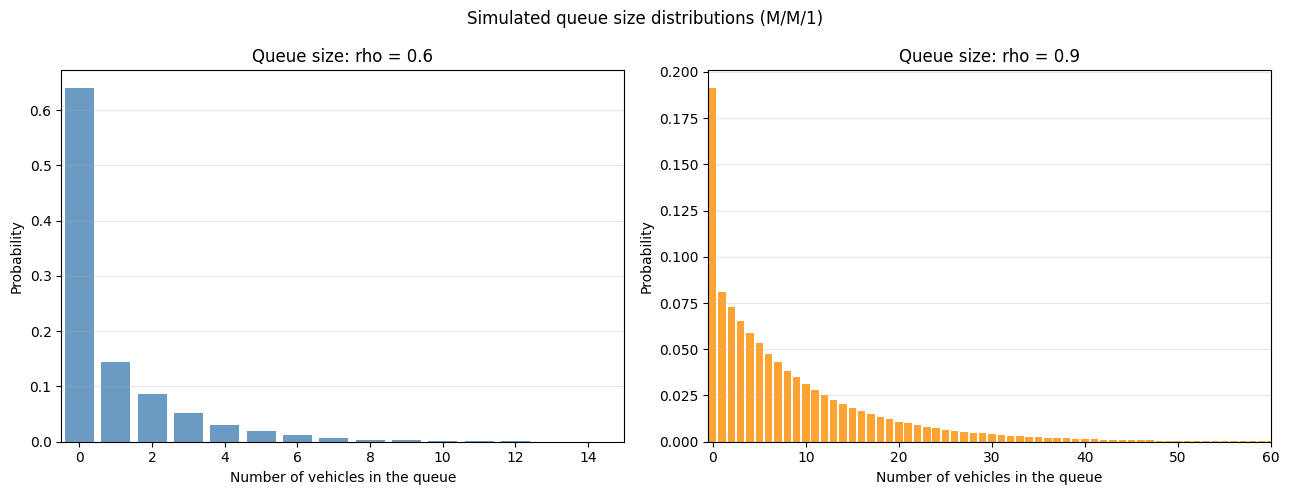

In [ ]:
def queue_distribution(sim):

    state_durations = {}

    for values in sim.get_simulation_records().values():

        queue = values["queue"][50:]

        times = queue[:, 0]
#Gets the number of waiting vehicles excluding the one being served and converts it to integers
        states = np.maximum(queue[:-1, 1] - 1, 0).astype(int)
        durations = np.diff(times)

#Pairs each queue length with its duration. Adds the duration to the total time spent at that queue length
        for state, duration in zip(states, durations):
            state_durations[state] = (
                state_durations.get(state, 0) + duration
            )

    total_time = sum(state_durations.values())

    states = sorted(state_durations.keys())
    probabilities = [
        state_durations[state] / total_time
        for state in states
    ]

    return states, probabilities

states_06, probs_06 = queue_distribution(sim_06)
states_09, probs_09 = queue_distribution(sim_09)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# rho = 0.6
axes[0].bar(
    states_06, probs_06,
    color="steelblue", alpha=0.8
)

axes[0].set_title("Queue size: rho = 0.6")
axes[0].set_xlabel("Number of vehicles in the queue")
axes[0].set_ylabel("Probability")
axes[0].set_xlim(-0.5, 15)
axes[0].grid(axis="y", alpha=0.3)

# rho = 0.9
axes[1].bar(
    states_09, probs_09,
    color="darkorange", alpha=0.8
)

axes[1].set_title("Queue size: rho = 0.9")
axes[1].set_xlabel("Number of vehicles in the queue")
axes[1].set_ylabel("Probability")
axes[1].set_xlim(-0.5, 60)
axes[1].grid(axis="y", alpha=0.3)

plt.suptitle("Simulated queue size distributions (M/M/1)")
plt.tight_layout()
plt.show()

**What is the probability that the waiting time is higher than 3 minutes? plot the distribution of simulated waiting times**

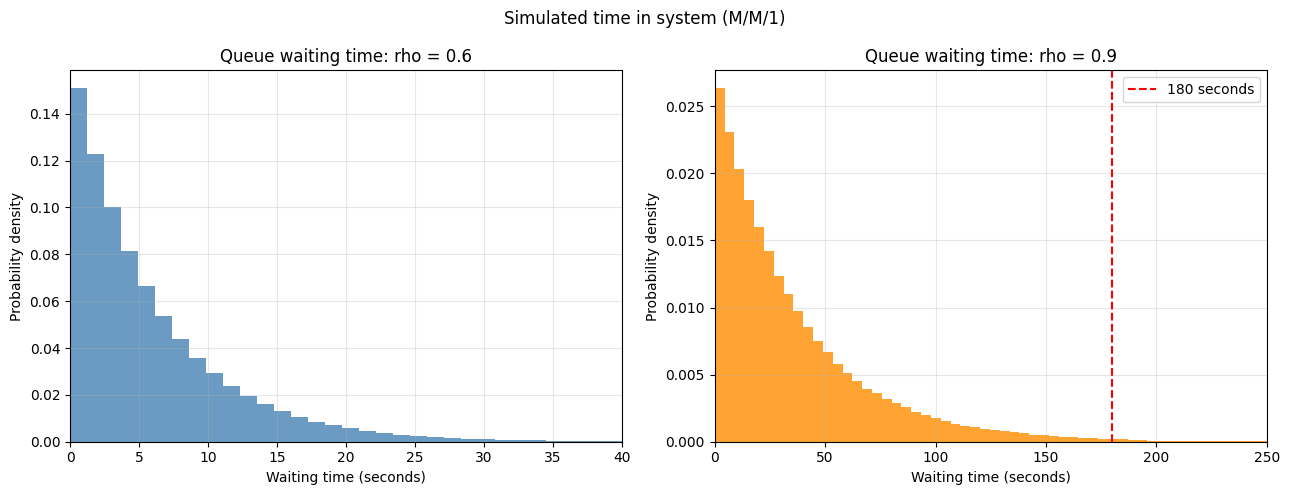

P(W > 180 s), rho = 0.6: 0.0
P(W > 180 s), rho = 0.9: 0.006366191346658334


In [ ]:
def get_waiting_times(sim):

    all_times = []

    for values in sim.get_simulation_records().values():

        A = values["A"][50:]
        D = values["D"][50:]

        waiting_times = (D - A) * 60

        all_times.extend(waiting_times)

    return np.array(all_times)

waiting_06 = get_waiting_times(sim_06)
waiting_09 = get_waiting_times(sim_09)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Only positive waiting times
positive_06 = waiting_06
positive_09 = waiting_09

# rho = 0.6
axes[0].hist(positive_06, bins=60, density=True,
             color="steelblue", alpha=0.8)

axes[0].set_title("Queue waiting time: rho = 0.6")
axes[0].set_xlabel("Waiting time (seconds)")
axes[0].set_ylabel("Probability density")
axes[0].set_xlim(0, 40)
axes[0].grid(alpha=0.3)

# rho = 0.9
axes[1].hist(positive_09, bins=80, density=True,
             color="darkorange", alpha=0.8)

axes[1].axvline(180, color="red", linestyle="--",
                label="180 seconds")

axes[1].set_title("Queue waiting time: rho = 0.9")
axes[1].set_xlabel("Waiting time (seconds)")
axes[1].set_ylabel("Probability density")
axes[1].set_xlim(0, 250)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Simulated time in system (M/M/1)")
plt.tight_layout()
plt.show()

print("P(W > 180 s), rho = 0.6:", np.mean(waiting_06 > 180))
print("P(W > 180 s), rho = 0.9:", np.mean(waiting_09 > 180))

**Check if N=100 is large enough to fulfill accuracy (confidence interval)**

In [ ]:
from scipy.stats import t

def check_accuracy(sim):
    run_means = []
    run_variances = []
    run_probabilities = []

    for values in sim.get_simulation_records().values():
        queue = values["queue"][50:]

        times = queue[:, 0]
        lengths = np.maximum(queue[:-1, 1] - 1, 0)
        durations = np.diff(times)

        # Mean queue length
        mean = np.sum(lengths * durations) / np.sum(durations)
        run_means.append(mean)

        # Variance of queue length
        variance = np.sum(
            (lengths - mean)**2 * durations
        ) / np.sum(durations)
        run_variances.append(variance)

        # Probability of waiting longer than 3 minutes
        A = values["A"][50:]
        D = values["D"][50:]

        waiting_times = D - A  # minutes
        probability = np.mean(waiting_times > 3)
        run_probabilities.append(probability)

    results = {
        "Mean queue length": run_means,
        "Queue length variance": run_variances,
        "P(wait > 180 s)": run_probabilities
    }

    N = len(run_means)

    for name, observations in results.items():
        observations = np.array(observations)

        estimate = np.mean(observations)
        std = np.std(observations, ddof=1)
        margin = t.ppf(0.975, N - 1) * std / np.sqrt(N)

        relative_error = (
            margin / estimate * 100
            if estimate > 0 else np.nan
        )

        print(f"\n{name}")
        print(f"Estimate: {estimate:.6f}")
        print(f"95% CI: [{estimate-margin:.6f}, {estimate+margin:.6f}]")
        print(f"Relative margin of error: {relative_error:.2f}%")

        if np.isnan(relative_error):
            print("Accuracy: Cannot assess (zero observed events)")
        elif relative_error < 5:
            print("Accuracy: Meets 5% target")
        else:
            print("Accuracy: Does not meet 5% target")

In [ ]:
sim_06.run_multiple_simulations(500)
sim_09.run_multiple_simulations(500)

print("========== rho = 0.6 ==========")
check_accuracy(sim_06)

print("\n========== rho = 0.9 ==========")
check_accuracy(sim_09)

========== rho = 0.6 ==========

Mean queue length
Estimate: 0.897460
95% CI: [0.893128, 0.901791]
Relative margin of error: 0.48%
Accuracy: Meets 5% target

Queue length variance
Estimate: 2.765411
95% CI: [2.735264, 2.795557]
Relative margin of error: 1.09%
Accuracy: Meets 5% target

P(wait > 180 s)
Estimate: 0.000000
95% CI: [0.000000, 0.000000]
Relative margin of error: nan%
Accuracy: Cannot assess (zero observed events)

========== rho = 0.9 ==========

Mean queue length
Estimate: 7.982607
95% CI: [7.856165, 8.109049]
Relative margin of error: 1.58%
Accuracy: Meets 5% target

Queue length variance
Estimate: 83.807508
95% CI: [79.840383, 87.774633]
Relative margin of error: 4.73%
Accuracy: Meets 5% target

P(wait > 180 s)
Estimate: 0.006306
95% CI: [0.005168, 0.007444]
Relative margin of error: 18.04%
Accuracy: Does not meet 5% target


# **Q2**

In [ ]:
class DeterministicServerQueueingSimulation():
    """
    This class simulates a single-server queueing system using discrete event simulation.
    The system models customer arrivals and service at a single server.
    It collects data on queue length, arrival times, and departure times.
    """

    def __init__(self, arrival_rate, service_rate, close_time):
        """
        Initializes the simulation with the given parameters.

        Parameters:
        - arrival_rate: The rate (per minute) at which customers arrive.
        - service_rate: The rate (per minute) at which the server can serve customers.
        - close_time: The time (in minutes) after which no new customers are allowed to join the queue.
        """
        self.arrival_rate = arrival_rate  # Set the customer arrival rate.
        self.service_rate = service_rate  # Set the service rate for the server.
        self.close_time = close_time  # Time after which no new arrivals are permitted.

        # Use a exponential random number generator with different seeds to model arrival and service times in simulation runs.
        self.arrival_rng = np.random.default_rng(seed=42)
        self.service_rng = np.random.default_rng(seed=123)

        # Dictionary to store the results of each simulation run.
        self.simulation_records = {}

    def simulate(self):
        """
        Runs a single instance of the queueing simulation.

        Tracks the current time, the number of arrivals and departures, and records
        arrival and departure times. The simulation runs until all customers have been served
        after the system closes to new arrivals.

        Returns:
        - queue: A record of the number of vehicles in the queue over time.
        - A: A record of arrival times.
        - D: A record of departure times.
        """

        # Initialize simulation state variables
        t = 0
        n = 0
        N_A = 0
        N_D = 0

        queue = []
        A = []
        D = []
        S = []

        t_A = t + self.arrival_rng.exponential(
            scale=1/self.arrival_rate
        )

        t_D = np.inf

        # Main simulation loop to process events (arrivals or departures).
        while True:

            # Case 1: A customer arrives before the next departure and before the system closes.
            if t_A <= t_D and t_A <= self.close_time:

                t = t_A
                N_A += 1
                n += 1

                A.append(t)
                queue.append((t, n))

                t_A = t + self.arrival_rng.exponential(
                    scale=1/self.arrival_rate
                )

                if n == 1:
                    S.append(t)

                    t_D = t + 1 / self.service_rate

            # Case 2: A customer departs before the next arrival and before the system closes.
            elif t_D < t_A and t_D <= self.close_time:

                t = t_D
                N_D += 1
                n -= 1

                D.append(t)
                queue.append((t, n))

                if n == 0:
                    t_D = np.inf

                else:
                    S.append(t)

                    t_D = t + 1 / self.service_rate

            # Case 3: Stop the simulation if there are no more arrivals or departures.
            else:

                t_A = np.inf

                if n == 0:
                    break

                t = t_D
                N_D += 1
                n -= 1

                D.append(t)
                queue.append((t, n))

                if n == 0:
                    t_D = np.inf

                else:
                    S.append(t)

                    t_D = t + 1 / self.service_rate

        # Convert lists to NumPy arrays for easier manipulation and analysis.
        queue = np.array(queue)
        A = np.array(A)
        D = np.array(D)
        S = np.array(S)

        # Return the recored queue states, arrival times, and departure times.
        return queue, A, D, S

    def run_multiple_simulations(self, n_simulations):
        """
        Runs the simulation multiple times and stores the results in simulation_records.

        Parameters:
        - n_simulations: Number of simulation runs to perform.

        Populates the simulation_records dictionary with the queue, arrival, and
        departure data for each simulation.
        """
        for i in range(n_simulations):
            queue, A, D, S = self.simulate()  # Run a single simulation.

            # Store the results in the simulation_records dictionary.
            self.simulation_records[f"round_{i}"] = {'queue': queue, 'A': A, 'D': D, 'S': S}
        return

    def compute_average_queue_length(self):
        """
        Computes the average queue length across all simulation runs.

        Returns:
        - The mean and standard deviation of the average queue length over all runs.
        """
        warm_up_period = 50 # Number of points to exclude from the start of the simulation
        average_queue_length = []  # List to store average queue lengths from each run.
        for values in self.simulation_records.values():
            queue = values['queue']  # Get the queue data for the current simulation.
            # Calculate the average queue length
            # NOTE: first points can be excluded, we only want the queue length in the steady state
            # NOTE: the number of vehicles in the queue is NOT evenly distributed along the simulation time
            #      find a way to weight the queue length by the time spent at each queue length

            # Exclude the first 50 recorded events
            queue = queue[warm_up_period:]

            # Extract event times and queue sizes
            times = queue[:, 0]
            lengths = np.maximum(queue[:, 1] - 1, 0)

            # Time between consecutive events
            time_intervals = np.diff(times)

            # Time-weighted average queue size
            queue_length = np.sum(
                lengths[:-1] * time_intervals
            ) / np.sum(time_intervals)

            # Store the result for this simulation run
            average_queue_length.append(queue_length)

        # Return the overall mean and standard deviation of the average queue lengths.
        return np.mean(average_queue_length), np.std(average_queue_length)

    def compute_average_waiting_time(self):
        """
        Computes the average waiting time for customers across all simulation runs.

        Returns:
        - The mean and standard deviation of the average waiting times across all runs.
        """
        warm_up_period = 50 # Number of points to exclude from the start of the simulation
        average_waiting_time = []  # List to store average waiting times from each run.
        for values in self.simulation_records.values():
            A = values['A']  # Get the arrival times.
            D = values['D']  # Get the departure times.

            # Calculate the average waiting time
            # Exclude the first 50 vehicles
            A = A[warm_up_period:]
            D = D[warm_up_period:]

            # Calculate each vehicle's total time in the system
            waiting_times = D - A

            # Calculate the average for this simulation run
            waiting_time = np.mean(waiting_times)

            # Store the average
            average_waiting_time.append(waiting_time)

        # Return the mean and standard deviation of the average waiting times.
        return np.mean(average_waiting_time), np.std(average_waiting_time)

    def get_simulation_records(self):
        """
        Retrieves the recorded data from all simulation runs.

        Returns:
        - A dictionary containing the queue, arrival, and departure data for each simulation run.
        {
            'round_0': {
                'queue': queue,
                'A': A,
                'D': D,
            },
            'round_1': {...},
            'round_2': {...},
            ...
        }
        """
        return self.simulation_records

In [ ]:
sim_md_06 = DeterministicServerQueueingSimulation(
    arrival_rate=15,
    service_rate=25,
    close_time=1000
)

sim_md_09 = DeterministicServerQueueingSimulation(
    arrival_rate=15,
    service_rate=15/0.9,
    close_time=1000
)

# Run 100 simulations for each traffic intensity
sim_md_06.run_multiple_simulations(100)
sim_md_09.run_multiple_simulations(100)

# Calculate mean and standard deviation
mean_06, std_06 = sim_md_06.compute_average_queue_length()
mean_09, std_09 = sim_md_09.compute_average_queue_length()

print(f"ρ = 0.6: Mean = {mean_06:.2f}, Std = {std_06:.2f}")
print(f"ρ = 0.9: Mean = {mean_09:.2f}, Std = {std_09:.2f}")

ρ = 0.6: Mean = 0.45, Std = 0.02
ρ = 0.9: Mean = 4.09, Std = 0.49


In [ ]:
variance_md_06 = compute_queue_variance(sim_md_06)
variance_md_09 = compute_queue_variance(sim_md_09)

print(f"ρ = 0.6: Variance = {variance_md_06:.2f}")
print(f"ρ = 0.9: Variance = {variance_md_09:.2f}")

ρ = 0.6: Variance = 0.84
ρ = 0.9: Variance = 23.06


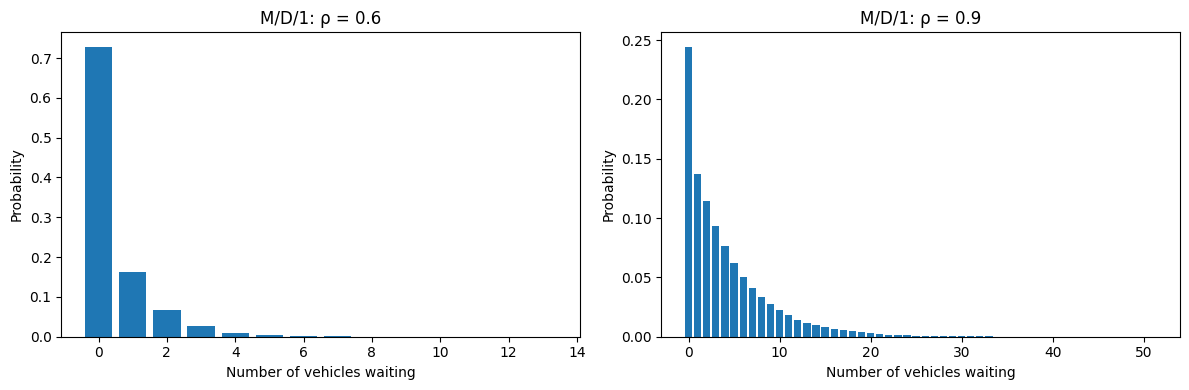

In [ ]:
dist_md_06 = queue_distribution(sim_md_06)
dist_md_09 = queue_distribution(sim_md_09)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, dist, rho in zip(
    axes,
    [dist_md_06, dist_md_09],
    [0.6, 0.9]
):
    queue_lengths, probabilities = dist

    ax.bar(queue_lengths, probabilities)
    ax.set_title(f"M/D/1: ρ = {rho}")
    ax.set_xlabel("Number of vehicles waiting")
    ax.set_ylabel("Probability")

plt.tight_layout()
plt.show()

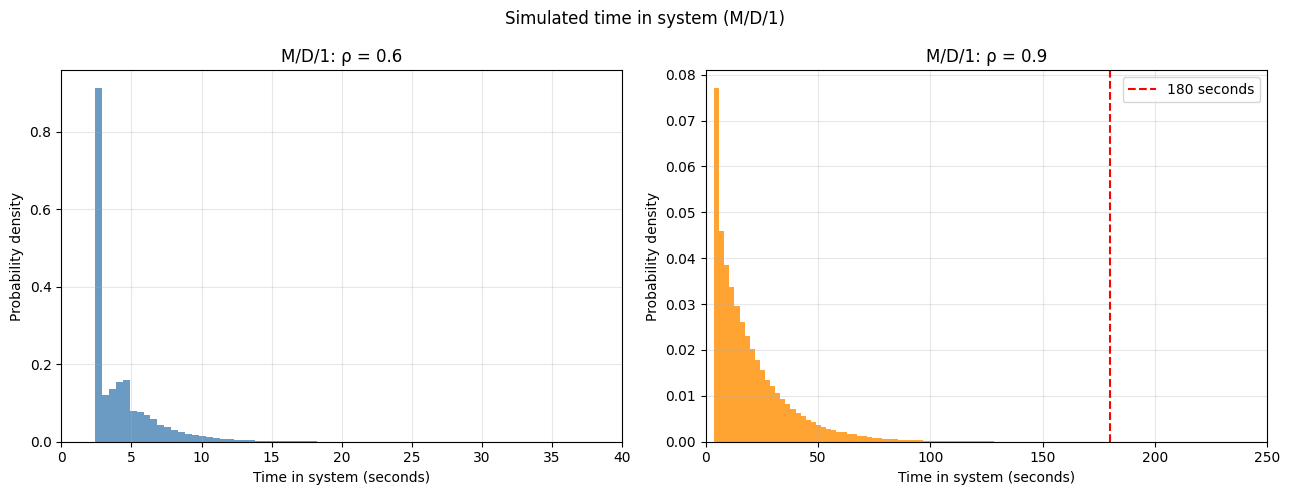

ρ = 0.6: P(W > 180 s) = 0.000000
ρ = 0.9: P(W > 180 s) = 0.000002


In [ ]:
waiting_md_06 = get_waiting_times(sim_md_06)
waiting_md_09 = get_waiting_times(sim_md_09)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(waiting_md_06, bins=60, density=True,
             color="steelblue", alpha=0.8)
axes[0].set_title("M/D/1: ρ = 0.6")
axes[0].set_xlabel("Time in system (seconds)")
axes[0].set_ylabel("Probability density")
axes[0].set_xlim(0, 40)
axes[0].grid(alpha=0.3)

axes[1].hist(waiting_md_09, bins=80, density=True,
             color="darkorange", alpha=0.8)
axes[1].axvline(180, color="red", linestyle="--",
                label="180 seconds")
axes[1].set_title("M/D/1: ρ = 0.9")
axes[1].set_xlabel("Time in system (seconds)")
axes[1].set_ylabel("Probability density")
axes[1].set_xlim(0, 250)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Simulated time in system (M/D/1)")
plt.tight_layout()
plt.show()

print(f"ρ = 0.6: P(W > 180 s) = {np.mean(waiting_md_06 > 180):.6f}")
print(f"ρ = 0.9: P(W > 180 s) = {np.mean(waiting_md_09 > 180):.6f}")

In [ ]:
sim_md_06.run_multiple_simulations(500)
sim_md_09.run_multiple_simulations(500)

print("M/D/1: rho = 0.6")
check_accuracy(sim_md_06)

print("\nM/D/1: rho = 0.9")
check_accuracy(sim_md_09)

M/D/1: rho = 0.6

Mean queue length
Estimate: 0.449351
95% CI: [0.447805, 0.450896]
Relative margin of error: 0.34%
Accuracy: Meets 5% target

Queue length variance
Estimate: 0.828947
95% CI: [0.823127, 0.834767]
Relative margin of error: 0.70%
Accuracy: Meets 5% target

P(wait > 180 s)
Estimate: 0.000000
95% CI: [0.000000, 0.000000]
Relative margin of error: nan%
Accuracy: Cannot assess (zero observed events)

M/D/1: rho = 0.9

Mean queue length
Estimate: 4.045418
95% CI: [4.000398, 4.090438]
Relative margin of error: 1.11%
Accuracy: Meets 5% target

Queue length variance
Estimate: 22.528687
95% CI: [21.850218, 23.207156]
Relative margin of error: 3.01%
Accuracy: Meets 5% target

P(wait > 180 s)
Estimate: 0.000018
95% CI: [-0.000003, 0.000038]
Relative margin of error: 117.90%
Accuracy: Does not meet 5% target



### It would be great if your report includes:
*   Derivation of the arrival time
*   Derivations of theortical values
*   Simulation parameters, result formats, result visualizations
*   Way to calculate the expected queue length and waiting time
*   Comparison of the theoretical results and simulated results (and maybe some reflections)
*   Probability that waiting time is greater than 3 minutes
*   Comparison of different parameters
*   What if the service rate is deterministic?
